<a href="https://colab.research.google.com/github/janpeter19/BPL_TEST2_Chemostat/blob/main/BPL_TEST2_Chemostat_oms_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BPL_TEST2_Chemostat script with OMSimulator

The key library OMSimulator is installed.

After the installation a small application BPL_TEST2_Chemostat is loaded and run. You can continue with this example if you like.

In [1]:
!lsb_release -a # Actual VM Ubuntu version used by Google

No LSB modules are available.
Distributor ID:	Ubuntu
Description:	Ubuntu 24.04.5 LTS
Release:	24.04
Codename:	noble


In [2]:
!python --version

Python 3.13.18


In [3]:
%pip install -q uv

In [4]:
!uv pip install OMSimulator # Install the key package

Using Python 3.13.18 environment at: /usr
Resolved 7 packages in 391ms
Prepared 1 package in 5.50s
Installed 1 package in 4ms
 + omsimulator==3.0.0.post198


In [11]:
!uv pip install --system git+https://github.com/janpeter19/FMU_explore.git@v1.2.6

Using Python 3.13.18 environment at: /usr
Resolved 1 package in 467ms
Prepared 1 package in 1.83s
Uninstalled 1 package in 0.78ms
Installed 1 package in 1ms
 - fmu-explore==1.2.4 (from git+https://github.com/janpeter19/FMU_explore.git@3c6c9e30cd9aa60f70e166afb9778d65e771e5da)
 + fmu-explore==1.2.6 (from git+https://github.com/janpeter19/FMU_explore.git@573ae8b5a2daf5d983a5cf2d98abbd78ab7da18e)


In [6]:
!uv pip install DyMat

Using Python 3.13.18 environment at: /usr
Resolved 1 package in 1.02s
Prepared 1 package in 382ms
Installed 1 package in 1ms
 + dymat==0.7


## Now specific installation run a simulation and notebook for that

Start with connecting to Github. Then upload the two files:

* FMU - BPL_TEST2_Chemostat_linux_om_me.fmu
* Setup-file - BPL_TEST2_Chemostat_oms.py
* Setup-file - BPL_TEST2_Chemostat_oms_explore.py

In [22]:
%%bash
git clone https://github.com/janpeter19/BPL_TEST2_Chemostat

Cloning into 'BPL_TEST2_Chemostat'...


In [23]:
%cd BPL_TEST2_Chemostat

/content/BPL_TEST2_Chemostat/BPL_TEST2_Chemostat/BPL_TEST2_Chemostat


## BPL_TEST2_Chemostat - demo

In [24]:
# Import the application model and context variables
from BPL_TEST2_Chemostat_oms import*

In [27]:
# Import the general FMU_explore functions and adapt them to the application
from fmu_explore_oms import AdaptWith

Application = AdaptWith(parValue, parLocation, parCheck, \
                        fmu_model, fmu_process_diagram, \
                        MSL_usage, MSL_version, BPL_version, \
                        options, simulationTime, timeDiscreteStates, \
                        diagrams, ax, lines)

par = Application.par
init = Application.init
#disp = Application.disp
simu = Application.simu
show = Application.show

resetPen = Application.resetPen
process_diagram = Application.process_diagram
#describe_general = Application.describe_general
#describe_parts = Application.describe_parts
describe_MSL = Application.describe_MSL
#cstrProdMax = Application.external_function

FMU_explore_info = Application.FMU_explore_info
system_info = Application.system_info
SDG = Application.SDG

In [28]:
run -i BPL_TEST2_Chemostat_oms_explore.py


Model for the process has been setup. Key commands:
 - par()       - change of parameters and initial values
 - init()      - change initial values only
 - simu()      - simulate and plot
 - newplot()   - make a new plot
 - show()      - show plot from previous simulation
 - disp()      - display parameters and initial values from the last simulation
 - describe()  - describe culture, broth, parameters, variables with values/units

Note that both disp() and describe() takes values from the last simulation
and the command process_diagram() brings up the main configuration

Brief information about a command by help(), eg help(simu)
Key system information is listed with the command system_info()


In [29]:
%matplotlib inline
plt.rcParams['figure.figsize'] = [25/2.54, 20/2.54]

In [30]:
#describe('process')

In [31]:
describe('culture')

Simplified text book model - only substrate S and cell concentration X


No processDiagram.png file in the FMU, but try the file on disk.


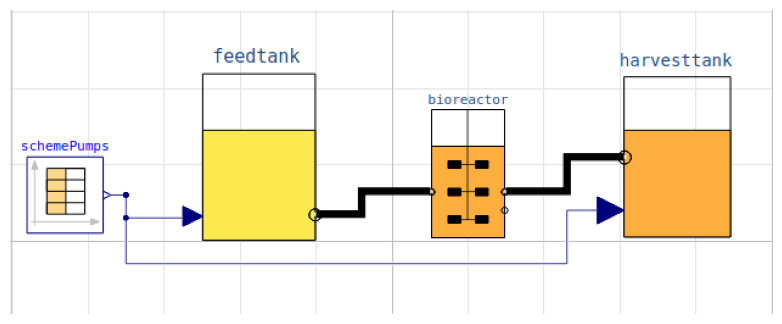

In [32]:
process_diagram()

KeyError: 'D'

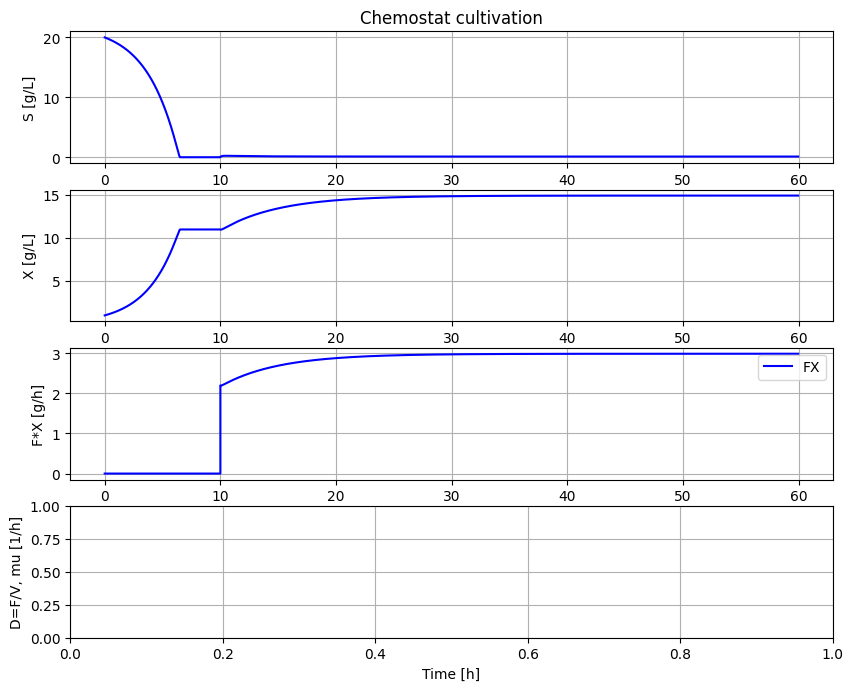

In [33]:
newplot()
par(Y=0.50, qSmax=0.75,  Ks=0.1)               # Culture parameters
init(V_start=1.0, VX_start=1.0, VS_start=20)   # Bioreactor startup
par(S_in=30, t0=0, F0=0, t1=10, F1=0.2)        # Substrate feeding
simu(60)

In [ ]:
# Test simu('cont')
newplot()
simu(20)
simu(40,'cont')

In [ ]:
#describe('parts')

In [34]:
describe('MSL')

MSL: 4.1.0 - used components: RealInput, RealOutput, CombiTimeTable, Types


In [35]:
system_info()


System information
 -OS: Linux
 -Python: 3.13.18
 -Scipy: 1.16.3
 -OMSimulator: 3.0.0.post198
 -FMU by: OpenModelica Compiler OpenModelica 1.26.3~1-g7583224
 -FMI: 2.0
 -Type: me
 -Name: BPL.Examples_TEST2.Chemostat
 -Generated: 2026-04-11T11:36:15Z
 -MSL: 4.1.0
 -Description: Bioprocess Library version 2.3.2
 -Interaction: FMU_explore version 1.2.6


In [36]:
!lsb_release -d

No LSB modules are available.
Description:	Ubuntu 24.04.5 LTS


In [37]:
SDG()